# 04a · Modelamiento de Lucas: popularidad histórica de canciones

**Responsable:** Lucas Moncada · **Etapas CRISP-DM:** Modeling y Evaluation.

**Pregunta:** ¿cuánta señal aportan los atributos musicales y los géneros para estimar la
`popularity` histórica de esta muestra? Se comparan una referencia mediana, Ridge y un árbol de
regresión. Después se buscan perfiles musicales con K-Means. El experimento personal compara cada
regresor con y sin `track_genres`.

Este notebook aplica el [protocolo aprobado](../docs/ea2/protocolo_comun.md). La fuente fue
muestreada por género y no tiene fechas de extracción ni exposición promocional; los resultados
son retrospectivos y no prueban que un atributo cause popularidad ni que el modelo anticipe
éxito comercial futuro.

Los comandos para instalar dependencias, regenerar datos y ejecutar todas las celdas están en
[las instrucciones de reproducción de Lucas](../docs/ea2/lucas.md).

## 1. Fuente, preparación y controles

La EP1 halló 89.740 canciones únicas, 10,47% con popularidad cero y 3,48% con popularidad ≥ 70.
También encontró asociaciones acústicas individuales débiles, redundancia entre `energy` y
`loudness`, y una muestra artificialmente balanceada por género. Por eso se conserva una referencia
simple, se analizan errores por rangos y se evita extrapolar la prevalencia al catálogo completo.
Se regenera el procesado desde el CSV original con las reglas ya aprobadas, sin editar la fuente.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

from spotify_popularity.analysis.exploratory import validate_processed_dataset
from spotify_popularity.config import PROJECT_PATHS
from spotify_popularity.data.loader import load_raw_dataset
from spotify_popularity.data.preparation import prepare_modeling_dataset
from spotify_popularity.data.provenance import sha256_file
from spotify_popularity.modeling.protocol import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    SEED,
    audio_pipeline,
    genre_only_pipeline,
    model_pipeline,
    primary_artist,
    regression_metrics,
    split_primary_artist_ids,
    split_track_ids,
    top_decile_kpi,
)

source_hash = sha256_file(PROJECT_PATHS.raw_dataset)
data, preparation = prepare_modeling_dataset(load_raw_dataset())
controls = validate_processed_dataset(data)
assert controls["shape"] == (89_740, 20)
assert controls["missing_cells"] == 0
assert controls["duplicate_track_ids"] == 0
assert controls["non_positive_durations"] == 0
assert controls["empty_genres"] == 0
assert data["popularity"].between(0, 100).all()
print(f"Fuente SHA-256: {source_hash}")
print(f"scikit-learn/pandas: {sklearn.__version__} / {pd.__version__}")
print(f"Preparación: {preparation}")
display(pd.Series(controls, name="valor").to_frame())

Fuente SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
scikit-learn/pandas: 1.9.0 / 2.3.3
Preparación: PreparationSummary(input_rows=114000, invalid_rows_removed=1, output_rows=89740, repeated_track_ids_consolidated=24259)


,valor
shape,"(89740, 20)"
missing_cells,0
unique_track_ids,89740
duplicate_track_ids,0
non_positive_durations,0
empty_genres,0


## 2. Partición común y prevención de fuga

La unidad es `track_id`, ya deduplicada. Se ordenan los IDs antes de una separación 80/20 con
semilla 42; del entrenamiento se aparta 20% para validación. El conjunto de prueba queda reservado
hasta que se fijan parámetros y candidato recomendado. `track_id`, artistas, títulos y la variable
objetivo no entran en la matriz de predictores. La escala y los codificadores se ajustan dentro de
cada pipeline usando solo las filas disponibles para ese ajuste.

In [2]:
split = split_track_ids(data)
feature_columns = list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES) + ["track_genres"]
indexed = data.set_index("track_id", drop=False)
fit_data = indexed.loc[list(split.fit_ids)]
validation_data = indexed.loc[list(split.validation_ids)]
train_data = indexed.loc[list(split.train_ids)]
test_data = indexed.loc[list(split.test_ids)]

X_fit, y_fit = fit_data[feature_columns], fit_data["popularity"]
X_validation, y_validation = validation_data[feature_columns], validation_data["popularity"]
X_train, y_train = train_data[feature_columns], train_data["popularity"]
X_test, y_test = test_data[feature_columns], test_data["popularity"]
assert not set(split.train_ids).intersection(split.test_ids)
assert set(split.fit_ids).union(split.validation_ids) == set(split.train_ids)
assert len(split.train_ids) == 71_792 and len(split.test_ids) == 17_948

print(f"Semilla: {SEED}")
print(
    f"Ajuste: {len(X_fit):,}; validación: {len(X_validation):,}; "
    f"entrenamiento total: {len(X_train):,}; prueba: {len(X_test):,}"
)
print(f"SHA-256 de IDs de prueba ordenados: {split.test_sha256}")
display(
    pd.DataFrame(
        {
            "partición": ["ajuste", "validación", "prueba"],
            "canciones": [len(X_fit), len(X_validation), len(X_test)],
            "popularidad_media": [y_fit.mean(), y_validation.mean(), y_test.mean()],
            "proporción_70_o_más": [
                y_fit.ge(70).mean(),
                y_validation.ge(70).mean(),
                y_test.ge(70).mean(),
            ],
        }
    ).round(3)
)

Semilla: 42
Ajuste: 57,433; validación: 14,359; entrenamiento total: 71,792; prueba: 17,948
SHA-256 de IDs de prueba ordenados: 7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318


,partición,canciones,popularidad_media,proporción_70_o_más
0,ajuste,57433,33.138,0.035
1,validación,14359,33.174,0.033
2,prueba,17948,33.411,0.036


## 3. Algoritmos y selección con validación

`popularity` es numérica, por lo que se modela como regresión. La referencia predice la mediana
del entrenamiento y fija el error que debe superarse en MAE. Ridge regulariza una combinación
lineal y ayuda frente a predictores correlacionados; el árbol puede capturar umbrales e
interacciones, pero puede sobreajustar. Antes de consultar la prueba se comparan los `alpha` 0,1,
1, 10 y 100, y los árboles de profundidad 5, 10 o 15 con hojas mínimas de 20 o 100. Se elige por
MAE de validación, RMSE y menor complejidad para desempatar. Cada variante usa exactamente los
mismos IDs; la única diferencia del experimento personal es incluir `track_genres`.

In [3]:
ridge_grid = [{"alpha": alpha} for alpha in (0.1, 1.0, 10.0, 100.0)]
tree_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf} for depth in (5, 10, 15) for leaf in (20, 100)
]


def estimator_for(model_name, parameters):
    if model_name == "Ridge":
        return Ridge(**parameters)
    return DecisionTreeRegressor(random_state=SEED, **parameters)


reference_validation = DummyRegressor(strategy="median").fit(X_fit, y_fit)
reference_validation_metrics = regression_metrics(
    y_validation, reference_validation.predict(X_validation)
)
validation_rows = []
for variant, include_genres in (("completo", True), ("sin_géneros", False)):
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            estimator_name = "Ridge" if model_name == "Ridge" else "Árbol"
            pipeline = model_pipeline(
                estimator_for(estimator_name, parameters), include_genres=include_genres
            )
            pipeline.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, pipeline.predict(X_validation))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

validation = pd.DataFrame(validation_rows)
selected = (
    validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .sort_values(["variante", "MAE"])
    .reset_index(drop=True)
)
print("Referencia en validación:", reference_validation_metrics)
display(validation.sort_values(["variante", "modelo", "MAE"]).round(3))
print("Configuraciones seleccionadas usando solo validación:")
display(selected.round(3))

full_candidates = selected.loc[selected["variante"].eq("completo")].sort_values(
    ["MAE", "RMSE", "complejidad"]
)
recommended_before_test = (
    full_candidates.iloc[0]["modelo"]
    if full_candidates.iloc[0]["MAE"] < reference_validation_metrics["MAE"]
    else "Referencia"
)
print("Candidato recomendado antes de abrir la prueba:", recommended_before_test)

Referencia en validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,completo,Ridge,{'alpha': 1.0},-1.0,11.788,16.430,0.360
2,completo,Ridge,{'alpha': 10.0},-10.0,11.818,16.435,0.359
3,completo,Ridge,{'alpha': 100.0},-100.0,12.169,16.574,0.349
8,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
9,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14900.0,14.442,18.360,0.201
6,completo,Árbol,"{'max_depth': 10, 'min_samples_leaf': 20}",9980.0,15.088,18.827,0.159
7,completo,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",9900.0,15.109,18.852,0.157
4,completo,Árbol,"{'max_depth': 5, 'min_samples_leaf': 20}",4980.0,15.896,19.496,0.099
5,completo,Árbol,"{'max_depth': 5, 'min_samples_leaf': 100}",4900.0,15.898,19.496,0.099


Configuraciones seleccionadas usando solo validación:


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,15.627,19.830,0.067
3,sin_géneros,Ridge,{'alpha': 0.1},-0.1,16.581,20.162,0.036


Candidato recomendado antes de abrir la prueba: Ridge


## 4. Evaluación final en la prueba reservada

Se reajustan las cuatro configuraciones seleccionadas con las 71.792 canciones de entrenamiento.
La prueba se consulta una vez para las variantes declaradas de antemano. MAE y RMSE se expresan en
puntos de popularidad; RMSE penaliza más los errores grandes. R² compara el error cuadrático con
una constante igual a la media observada en la prueba; puede ser negativo. La diferencia de MAE
contra la referencia mediana muestra si el modelo aporta algo en esta muestra.

,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
1,completo,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
2,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.508,18.460,0.198,2.742,15.898
0,referencia,Referencia,mediana,17.250,20.612,-0.000,0.000,0.000
3,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.693,19.834,0.074,1.557,9.026
4,sin_géneros,Ridge,{'alpha': 0.1},16.671,20.223,0.037,0.580,3.360


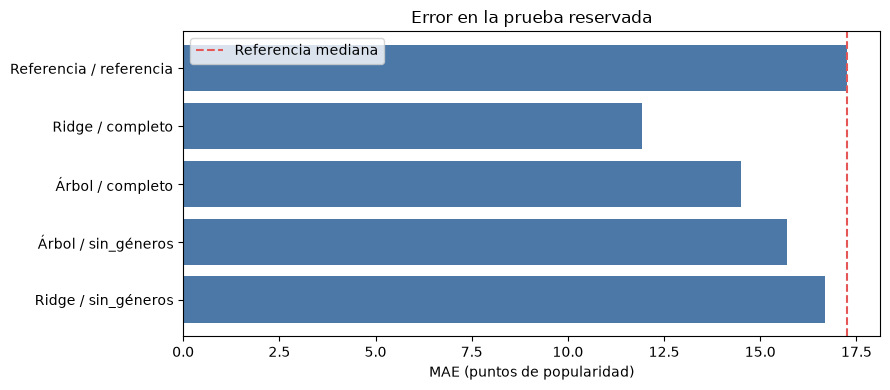

In [4]:
reference = DummyRegressor(strategy="median").fit(X_train, y_train)
predictions = {"Referencia": reference.predict(X_test)}
test_rows = [
    {
        "variante": "referencia",
        "modelo": "Referencia",
        "parámetros": "mediana",
        **regression_metrics(y_test, predictions["Referencia"]),
    }
]

for row in selected.itertuples(index=False):
    name = f"{row.modelo} / {row.variante}"
    pipeline = model_pipeline(
        estimator_for(row.modelo, row.parámetros),
        include_genres=row.variante == "completo",
    )
    pipeline.fit(X_train, y_train)
    predictions[name] = pipeline.predict(X_test)
    test_rows.append(
        {
            "variante": row.variante,
            "modelo": row.modelo,
            "parámetros": row.parámetros,
            **regression_metrics(y_test, predictions[name]),
        }
    )

test_scores = pd.DataFrame(test_rows)
baseline_mae = test_scores.loc[test_scores["modelo"].eq("Referencia"), "MAE"].iloc[0]
test_scores["mejora_MAE_puntos"] = baseline_mae - test_scores["MAE"]
test_scores["mejora_MAE_pct"] = 100 * test_scores["mejora_MAE_puntos"] / baseline_mae
display(test_scores.sort_values(["variante", "MAE"]).round(3))

plot_scores = test_scores.copy()
plot_scores["etiqueta"] = plot_scores["modelo"] + " / " + plot_scores["variante"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot_scores["etiqueta"], plot_scores["MAE"], color="#4C78A8")
ax.axvline(baseline_mae, color="#E45756", linestyle="--", label="Referencia mediana")
ax.set(xlabel="MAE (puntos de popularidad)", title="Error en la prueba reservada")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04a_lucas_model_mae.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

## 5. KPI retrospectivo y errores por segmentos

El umbral ≥ 70 proviene de EP1 y la capacidad de revisión se fija en el 10% antes de ver la prueba.
La precisión de esa lista se compara con la prevalencia en **esta muestra**; `lift > 1` significaría
un ranking mejor que una selección aleatoria de igual tamaño aquí, no utilidad comercial probada.
Se informa también qué proporción de todas las canciones ≥ 70 recupera la lista. Los rangos de
popularidad reales solo se usan para diagnosticar errores después de predecir.

In [5]:
kpi_rows = []
for name, predicted in predictions.items():
    kpi_rows.append({"modelo": name, **top_decile_kpi(test_data["track_id"], y_test, predicted)})
kpi = pd.DataFrame(kpi_rows).sort_values("lift", ascending=False)
display(kpi.round(3))

diagnostic_name = (
    "Referencia"
    if recommended_before_test == "Referencia"
    else f"{recommended_before_test} / completo"
)
errors = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "predicho": predictions[diagnostic_name],
        "explicit": test_data["explicit"].to_numpy(),
    }
)
errors["error_absoluto"] = (errors["actual"] - errors["predicho"]).abs()
errors["rango"] = np.select(
    [
        errors["actual"].eq(0),
        errors["actual"].between(0, 35, inclusive="neither"),
        errors["actual"].between(35, 70, inclusive="left"),
        errors["actual"].ge(70),
    ],
    ["0", "(0,35)", "[35,70)", "[70,100]"],
    default="fuera_de_rango",
)
print("Diagnóstico del candidato fijado en validación:", diagnostic_name)
display(
    errors.groupby("rango", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)
display(
    errors.groupby("explicit", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)

,modelo,seleccionadas,populares_en_seleccion,populares_en_prueba,prevalencia,precision,recall,lift
1,Ridge / completo,1795,159,653,0.036,0.089,0.243,2.435
4,Ridge / sin_géneros,1795,136,653,0.036,0.076,0.208,2.082
2,Árbol / completo,1795,119,653,0.036,0.066,0.182,1.822
3,Árbol / sin_géneros,1795,82,653,0.036,0.046,0.126,1.256
0,Referencia,1795,63,653,0.036,0.035,0.096,0.965


Diagnóstico del candidato fijado en validación: Ridge / completo


,canciones,MAE
rango,,
"(0,35)",7361,8.040
"[35,70)",8071,10.546
0,1863,24.448
"[70,100]",653,36.759


,canciones,MAE
explicit,,
False,16431,11.704
True,1517,14.198


### Predicción frente al valor real y errores extremos

Se visualizan todas las canciones de la prueba aleatoria con un mapa de densidad; la diagonal
representa predicción perfecta. Para explicar los errores grandes se mide el sesgo firmado
(`predicho − real`) en los rangos ya fijados, se cuentan los errores absolutos de al menos 40
puntos y se inspeccionan los diez mayores. Es un diagnóstico posterior a la selección del modelo:
no se ajustan parámetros ni se cambia el umbral del KPI usando estos casos.

Predicciones mínima/máxima: -31.63632282507791 79.70606587058116
Predicciones fuera de [0, 100]: 76 por debajo de 0 y 0 por encima de 100
Errores absolutos ≥ 40: 651 de 17948
Entre ellos, popularidad ≥ 70: 236 ; popularidad 0: 278
Canciones ≥ 70 predichas por debajo de 70: 653 de 653


,canciones,real_mediana,predicho_mediana,sesgo_medio,MAE,error_p90
rango,,,,,,
"(0,35)",7361,22.0,27.367,6.344,8.040,16.593
"[35,70)",8071,48.0,41.106,-8.607,10.546,23.809
0,1863,0.0,23.369,24.148,24.448,42.249
"[70,100]",653,74.0,40.035,-36.759,36.759,56.233


,track_id,track_name,artists,track_genres,actual,predicho,error_absoluto
11899,2grjqo0Frpf2okIBiifQKs,September,"Earth, Wind & Fire",disco|funk|jazz|soul,83.0,-11.18,94.18
2006,1IHWl5LamUGEuP4ozKQSXZ,Tití Me Preguntó,Bad Bunny,latin|latino|reggae|reggaeton,97.0,8.74,88.26
6356,3k3NWokhRRkEPhCzPmV8TW,Ojitos Lindos,Bad Bunny;Bomba Estéreo,latin|latino|reggae|reggaeton,94.5,8.92,85.58
7105,5Eax0qFko2dh7Rl2lYs3bx,Efecto,Bad Bunny,latin|latino|reggae|reggaeton,95.5,10.39,85.11
8827,6Rqn2GFlmvmV4w9Ala0I1e,Feeling Good,Nina Simone,blues|jazz|soul,73.0,-6.11,79.11
7883,1oew3nFNY3vMacJAsvry0S,Me And My Broken Heart,Rixton,dance|rock,79.0,5.39,73.61
12726,1IqF5PUDUnaykHLs0RWbDO,Time Moves Slow,BADBADNOTGOOD;Samuel T. Herring,jazz|soul,71.0,-2.03,73.03
16238,2QjOHCTQ1Jl3zawyYOpxh6,Sweater Weather,The Neighbourhood,alt-rock|alternative|pop|rock,93.0,20.16,72.84
15796,2gam98EZKrF9XuOkU13ApN,Promiscuous,Nelly Furtado;Timbaland,latin,82.0,9.71,72.29
11495,737gzPI5VAmgUGWiJ9yXuu,"1, 2, 3 (feat. Jason Derulo & De La Ghetto)",Sofía Reyes;Jason Derulo;De La Ghetto,dance|latin|pop,73.0,1.02,71.98


Ranking de 10%: populares recuperadas / omitidas: 159 / 494 ; canciones seleccionadas sin llegar a 70: 1636


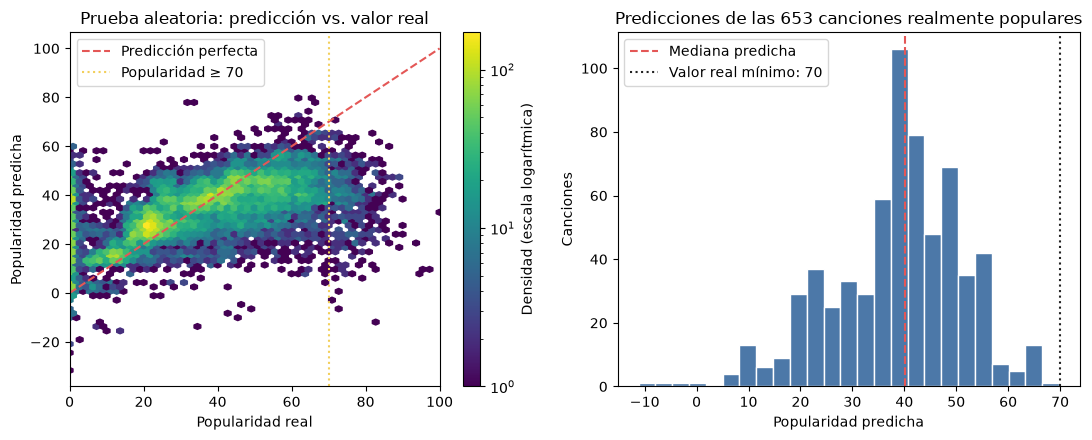

In [6]:
errors["track_id"] = test_data["track_id"].to_numpy()
errors["track_name"] = test_data["track_name"].to_numpy()
errors["artists"] = test_data["artists"].to_numpy()
errors["track_genres"] = test_data["track_genres"].to_numpy()
errors["sesgo"] = errors["predicho"] - errors["actual"]
high = errors.loc[errors["actual"].ge(70)]
extreme = errors.loc[errors["error_absoluto"].ge(40)]
print("Predicciones mínima/máxima:", errors["predicho"].min(), errors["predicho"].max())
print(
    "Predicciones fuera de [0, 100]:",
    errors["predicho"].lt(0).sum(),
    "por debajo de 0 y",
    errors["predicho"].gt(100).sum(),
    "por encima de 100",
)
print("Errores absolutos ≥ 40:", len(extreme), "de", len(errors))
print(
    "Entre ellos, popularidad ≥ 70:",
    extreme["actual"].ge(70).sum(),
    "; popularidad 0:",
    extreme["actual"].eq(0).sum(),
)
print("Canciones ≥ 70 predichas por debajo de 70:", high["predicho"].lt(70).sum(), "de", len(high))
display(
    errors.groupby("rango", sort=False)
    .agg(
        canciones=("actual", "size"),
        real_mediana=("actual", "median"),
        predicho_mediana=("predicho", "median"),
        sesgo_medio=("sesgo", "mean"),
        MAE=("error_absoluto", "mean"),
        error_p90=("error_absoluto", lambda values: values.quantile(0.90)),
    )
    .round(3)
)
display(
    errors.nlargest(10, "error_absoluto")[
        [
            "track_id",
            "track_name",
            "artists",
            "track_genres",
            "actual",
            "predicho",
            "error_absoluto",
        ]
    ].round(2)
)

ranked_errors = errors.sort_values(["predicho", "track_id"], ascending=[False, True])
top_capacity = int(np.ceil(len(errors) * 0.10))
top_errors = ranked_errors.iloc[:top_capacity]
popular_captured = int(top_errors["actual"].ge(70).sum())
print(
    "Ranking de 10%: populares recuperadas / omitidas:",
    popular_captured,
    "/",
    len(high) - popular_captured,
    "; canciones seleccionadas sin llegar a 70:",
    top_capacity - popular_captured,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
density = axes[0].hexbin(
    errors["actual"],
    errors["predicho"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="viridis",
)
axes[0].plot([0, 100], [0, 100], color="#E45756", linestyle="--", label="Predicción perfecta")
axes[0].axvline(70, color="#F2CF5B", linestyle=":", label="Popularidad ≥ 70")
axes[0].set(
    xlim=(0, 100),
    xlabel="Popularidad real",
    ylabel="Popularidad predicha",
    title="Prueba aleatoria: predicción vs. valor real",
)
axes[0].legend(loc="upper left")
fig.colorbar(density, ax=axes[0], label="Densidad (escala logarítmica)")
axes[1].hist(high["predicho"], bins=25, color="#4C78A8", edgecolor="white")
axes[1].axvline(
    high["predicho"].median(), color="#E45756", linestyle="--", label="Mediana predicha"
)
axes[1].axvline(70, color="#222222", linestyle=":", label="Valor real mínimo: 70")
axes[1].set(
    xlabel="Popularidad predicha",
    ylabel="Canciones",
    title=f"Predicciones de las {len(high)} canciones realmente populares",
)
axes[1].legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04a_lucas_predictions_vs_actual.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

### Qué cambia en el ranking al incluir géneros

Las variantes usan la misma prueba y la misma capacidad de **1.795 canciones**. Ridge completo
recuperó **159** de las **653** canciones con popularidad ≥ 70, frente a **136** sin géneros:
**23 recuperaciones adicionales**. Su precisión pasó de **7,6%** a **8,9%**, la exhaustividad de
**20,8%** a **24,3%** y el *lift* de **2,082** a **2,435**. En el árbol, las recuperaciones pasaron
de **82** sin géneros a **119** con géneros, y el *lift* de **1,256** a **1,822**. Esto concuerda
con la mejora de MAE al incorporar `track_genres`: las etiquetas ayudan también a ordenar esta
muestra. Aun en la mejor lista, **1.636 de 1.795** canciones seleccionadas no alcanzan el umbral,
y **494 de 653** populares quedan fuera. La comparación no prueba utilidad comercial ni un efecto
causal del género; el dataset fue muestreado artificialmente por esa variable.

## 6. Experimento personal: aporte de los géneros

Se comparan Ridge y árbol con las mismas canciones de ajuste, validación y prueba. La versión
`sin_géneros` elimina solo `track_genres`; las demás columnas y el procedimiento permanecen
idénticos. Cada versión seleccionó sus parámetros en validación. Una mejora puede reflejar la
estructura de esta muestra balanceada por género; no implica que el género cause popularidad ni
que la ganancia se reproduzca en un catálogo natural.

In [7]:
ablation = test_scores.loc[test_scores["modelo"].ne("Referencia")].pivot(
    index="modelo", columns="variante", values=["MAE", "RMSE", "R2"]
)
ablation["cambio_MAE_al_incluir_géneros"] = (
    ablation[("MAE", "sin_géneros")] - ablation[("MAE", "completo")]
)
display(ablation.round(3))

MAE                 RMSE                   R2              \
variante completo sin_géneros completo sin_géneros completo sin_géneros   
modelo                                                                    
Ridge      11.915      16.671   16.643      20.223    0.348       0.037   
Árbol      14.508      15.693   18.460      19.834    0.198       0.074   

         cambio_MAE_al_incluir_géneros  
variante                                
modelo                                  
Ridge                            4.756  
Árbol                            1.186

### Audio, géneros y ambos en validación

La comparación adicional usa **solo validación**, porque la prueba aleatoria ya fue consultada.
`solo_audio` incluye exactamente las diez variables numéricas musicales; `solo_géneros` usa solo
`track_genres`; `audio_y_géneros` combina esos dos conjuntos. No entran `key`, `mode`,
`time_signature` ni `explicit` en esta comparación específica. Se ajustan los mismos candidatos y
se eligen con MAE, RMSE y complejidad sobre los mismos IDs. Por separado, la comparación principal
`sin_géneros` versus `completo` elimina únicamente `track_genres` y conserva esas cuatro columnas
categóricas, según el protocolo aprobado.

In [8]:
feature_validation_rows = []
for variant in ("solo_audio", "solo_géneros", "audio_y_géneros"):
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            if variant == "solo_géneros":
                pipeline = genre_only_pipeline(estimator_for(model_name, parameters))
            else:
                pipeline = audio_pipeline(
                    estimator_for(model_name, parameters),
                    include_genres=variant == "audio_y_géneros",
                )
            pipeline.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, pipeline.predict(X_validation))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            feature_validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

feature_validation = pd.DataFrame(feature_validation_rows)
three_feature_sets = (
    feature_validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
)
display(
    three_feature_sets.sort_values(["modelo", "MAE"])[
        ["modelo", "variante", "parámetros", "MAE", "RMSE", "R2"]
    ].round(3)
)
print("Referencia mediana en la misma validación:", reference_validation_metrics)

,modelo,variante,parámetros,MAE,RMSE,R2
20,Ridge,audio_y_géneros,{'alpha': 0.1},11.800,16.449,0.358
10,Ridge,solo_géneros,{'alpha': 0.1},11.849,16.486,0.355
0,Ridge,solo_audio,{'alpha': 0.1},16.630,20.206,0.032
28,Árbol,audio_y_géneros,"{'max_depth': 15, 'min_samples_leaf': 20}",14.391,18.318,0.204
18,Árbol,solo_géneros,"{'max_depth': 15, 'min_samples_leaf': 20}",14.472,18.315,0.204
9,Árbol,solo_audio,"{'max_depth': 15, 'min_samples_leaf': 100}",15.686,19.570,0.092


Referencia mediana en la misma validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}


## 7. Diagnóstico de generalización por artista principal

El grupo es el primer nombre de `artists` antes de `;`, normalizado sin espacios laterales y sin
distinguir mayúsculas. Se crean prueba y validación con `GroupShuffleSplit` independiente de la
partición aleatoria; el 20% se aplica a grupos, por lo que las cantidades de canciones pueden
diferir. Ningún artista **principal** debe aparecer en dos particiones. Las colaboraciones con
artistas secundarios se cuentan aparte. Se repiten los mismos candidatos para `completo`,
`sin_géneros` y `solo_géneros`; se elige cada configuración dentro de la validación agrupada y se
reajusta con todo su
entrenamiento. La prueba agrupada es un diagnóstico secundario de esta muestra histórica, no una
estimación de rendimiento para lanzamientos futuros.

In [9]:
artist_split = split_primary_artist_ids(data)
artist_fit = indexed.loc[list(artist_split.fit_ids)]
artist_validation = indexed.loc[list(artist_split.validation_ids)]
artist_train = indexed.loc[list(artist_split.train_ids)]
artist_test = indexed.loc[list(artist_split.test_ids)]


def principal_set(frame):
    return set(frame["artists"].map(primary_artist))


def secondary_set(frame):
    return {
        name.strip().casefold()
        for artists in frame["artists"]
        for name in str(artists).split(";")[1:]
        if name.strip()
    }


assert not principal_set(artist_train) & principal_set(artist_test)
assert not principal_set(artist_fit) & principal_set(artist_validation)
assert set(artist_split.fit_ids) | set(artist_split.validation_ids) == set(artist_split.train_ids)
assert not set(artist_split.train_ids) & set(artist_split.test_ids)
shared_secondary = secondary_set(artist_train) & secondary_set(artist_test)
shared_secondary_as_principal = secondary_set(artist_test) & principal_set(artist_train)
shared_test_secondary = secondary_set(artist_test) & (
    secondary_set(artist_train) | principal_set(artist_train)
)
test_tracks_with_shared_secondary = sum(
    bool(
        {name.strip().casefold() for name in str(artists).split(";")[1:] if name.strip()}
        & shared_test_secondary
    )
    for artists in artist_test["artists"]
)
print("Partición agrupada, semilla:", SEED)
print(
    "Ajuste, validación, entrenamiento total, prueba:",
    len(artist_fit),
    len(artist_validation),
    len(artist_train),
    len(artist_test),
)
print(
    "Artistas principales en ajuste, validación, entrenamiento, prueba:",
    *map(
        lambda frame: len(principal_set(frame)),
        (artist_fit, artist_validation, artist_train, artist_test),
    ),
)
print(
    "Artistas principales compartidos entre entrenamiento y prueba:",
    len(principal_set(artist_train) & principal_set(artist_test)),
)
print("Artistas secundarios presentes en ambas particiones:", len(shared_secondary))
print(
    "Artistas secundarios de prueba que son principales en entrenamiento:",
    len(shared_secondary_as_principal),
)
print(
    "Artistas secundarios de prueba presentes en entrenamiento (cualquier rol):",
    len(shared_test_secondary),
)
print("Canciones de prueba con esos artistas secundarios:", test_tracks_with_shared_secondary)
print("SHA-256 de IDs de prueba agrupada:", artist_split.test_sha256)
display(
    pd.DataFrame(
        {
            "partición": ["ajuste", "validación", "prueba"],
            "canciones": [len(artist_fit), len(artist_validation), len(artist_test)],
            "artistas_principales": [
                len(principal_set(frame)) for frame in (artist_fit, artist_validation, artist_test)
            ],
            "popularidad_media": [
                frame["popularity"].mean() for frame in (artist_fit, artist_validation, artist_test)
            ],
            "proporción_70_o_más": [
                frame["popularity"].ge(70).mean()
                for frame in (artist_fit, artist_validation, artist_test)
            ],
        }
    ).round(3)
)

Partición agrupada, semilla: 42
Ajuste, validación, entrenamiento total, prueba: 57176 14371 71547 18193
Artistas principales en ajuste, validación, entrenamiento, prueba: 11288 2823 14111 3528
Artistas principales compartidos entre entrenamiento y prueba: 0
Artistas secundarios presentes en ambas particiones: 1415
Artistas secundarios de prueba que son principales en entrenamiento: 859
Artistas secundarios de prueba presentes en entrenamiento (cualquier rol): 1732
Canciones de prueba con esos artistas secundarios: 2633
SHA-256 de IDs de prueba agrupada: a76b54b8e2fd914db9dc5984ff77a8ac07e5b13bf0f36b7e371d048194e5ac52


,partición,canciones,artistas_principales,popularidad_media,proporción_70_o_más
0,ajuste,57176,11288,33.135,0.035
1,validación,14371,2823,32.252,0.034
2,prueba,18193,3528,34.144,0.036


In [10]:
X_artist_fit, y_artist_fit = artist_fit[feature_columns], artist_fit["popularity"]
X_artist_val, y_artist_val = artist_validation[feature_columns], artist_validation["popularity"]
X_artist_train, y_artist_train = artist_train[feature_columns], artist_train["popularity"]
X_artist_test, y_artist_test = artist_test[feature_columns], artist_test["popularity"]


def pipeline_for_variant(model_name, parameters, variant):
    estimator = estimator_for(model_name, parameters)
    if variant == "solo_géneros":
        return genre_only_pipeline(estimator)
    return model_pipeline(estimator, include_genres=variant == "completo")


artist_validation_rows = []
for variant in ("sin_géneros", "solo_géneros", "completo"):
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            pipeline = pipeline_for_variant(model_name, parameters, variant)
            pipeline.fit(X_artist_fit, y_artist_fit)
            scores = regression_metrics(y_artist_val, pipeline.predict(X_artist_val))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            artist_validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

artist_validation_scores = pd.DataFrame(artist_validation_rows)
artist_selected = (
    artist_validation_scores.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .sort_values(["variante", "modelo"])
    .reset_index(drop=True)
)
artist_reference_val = DummyRegressor(strategy="median").fit(X_artist_fit, y_artist_fit)
print(
    "Referencia en validación agrupada:",
    regression_metrics(y_artist_val, artist_reference_val.predict(X_artist_val)),
)
print("Selección independiente dentro de la partición agrupada:")
display(artist_selected[["variante", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

artist_reference = DummyRegressor(strategy="median").fit(X_artist_train, y_artist_train)
artist_test_rows = [
    {
        "variante": "referencia",
        "modelo": "Referencia",
        "parámetros": "mediana",
        **regression_metrics(y_artist_test, artist_reference.predict(X_artist_test)),
    }
]
for row in artist_selected.itertuples(index=False):
    pipeline = pipeline_for_variant(row.modelo, row.parámetros, row.variante)
    pipeline.fit(X_artist_train, y_artist_train)
    artist_test_rows.append(
        {
            "variante": row.variante,
            "modelo": row.modelo,
            "parámetros": row.parámetros,
            **regression_metrics(y_artist_test, pipeline.predict(X_artist_test)),
        }
    )
artist_test_scores = pd.DataFrame(artist_test_rows)
artist_baseline_mae = artist_test_scores.loc[
    artist_test_scores["modelo"].eq("Referencia"), "MAE"
].iloc[0]
artist_test_scores["mejora_MAE_puntos"] = artist_baseline_mae - artist_test_scores["MAE"]
artist_test_scores["mejora_MAE_pct"] = (
    100 * artist_test_scores["mejora_MAE_puntos"] / artist_baseline_mae
)
display(artist_test_scores.sort_values(["variante", "modelo"]).round(3))

comparable = pd.concat(
    [
        test_scores.assign(partición="aleatoria"),
        artist_test_scores.assign(partición="por_artista_principal"),
    ],
    ignore_index=True,
)
display(
    comparable.loc[
        comparable["variante"].isin(["referencia", "sin_géneros", "completo"]),
        ["partición", "variante", "modelo", "MAE", "RMSE", "R2", "mejora_MAE_puntos"],
    ]
    .sort_values(["modelo", "variante", "partición"])
    .round(3)
)

Referencia en validación agrupada: {'MAE': 17.423456961937234, 'RMSE': 20.750497251319622, 'R2': -0.0013008562675349555}
Selección independiente dentro de la partición agrupada:


,variante,modelo,parámetros,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},12.297,17.342,0.301
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.603,18.580,0.197
2,sin_géneros,Ridge,{'alpha': 0.1},16.796,20.332,0.039
3,sin_géneros,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",16.382,20.244,0.047
4,solo_géneros,Ridge,{'alpha': 0.1},12.346,17.412,0.295
5,solo_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.555,18.489,0.205


,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
1,completo,Ridge,{'alpha': 0.1},12.102,16.740,0.302,4.605,27.564
2,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.455,18.247,0.171,2.252,13.479
0,referencia,Referencia,mediana,16.707,20.075,-0.003,0.000,0.000
3,sin_géneros,Ridge,{'alpha': 0.1},16.245,19.855,0.019,0.462,2.765
4,sin_géneros,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",15.703,19.652,0.039,1.004,6.010
5,solo_géneros,Ridge,{'alpha': 0.1},12.120,16.763,0.301,4.587,27.458
6,solo_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.500,18.268,0.169,2.207,13.207


,partición,variante,modelo,MAE,RMSE,R2,mejora_MAE_puntos
0,aleatoria,referencia,Referencia,17.250,20.612,-0.000,0.000
5,por_artista_principal,referencia,Referencia,16.707,20.075,-0.003,0.000
1,aleatoria,completo,Ridge,11.915,16.643,0.348,5.335
6,por_artista_principal,completo,Ridge,12.102,16.740,0.302,4.605
4,aleatoria,sin_géneros,Ridge,16.671,20.223,0.037,0.580
8,por_artista_principal,sin_géneros,Ridge,16.245,19.855,0.019,0.462
2,aleatoria,completo,Árbol,14.508,18.460,0.198,2.742
7,por_artista_principal,completo,Árbol,14.455,18.247,0.171,2.252
3,aleatoria,sin_géneros,Árbol,15.693,19.834,0.074,1.557
9,por_artista_principal,sin_géneros,Árbol,15.703,19.652,0.039,1.004


## 8. K-Means: perfiles musicales sin usar el objetivo

El agrupamiento usa solo los diez atributos numéricos del entrenamiento y los escala antes de
calcular distancias. `popularity`, géneros, IDs y nombres quedan fuera. Se exploran K=2..8 con
inercia y silueta sobre una muestra reproducible de 2.000 canciones. La popularidad solo se resume
**después** de asignar grupos. La correlación entre algunos atributos y los extremos válidos pueden
influir en las distancias; el notebook integrador revisará esa sensibilidad.

,K,inercia,silueta_muestra,grupo_mínimo_pct
0,2,577883.661,0.245,24.767
1,3,519168.980,0.149,21.412
2,4,474263.881,0.152,7.817
3,5,434429.626,0.168,1.227
4,6,399967.676,0.166,1.209
5,7,369639.701,0.169,1.170
6,8,352524.864,0.176,0.043


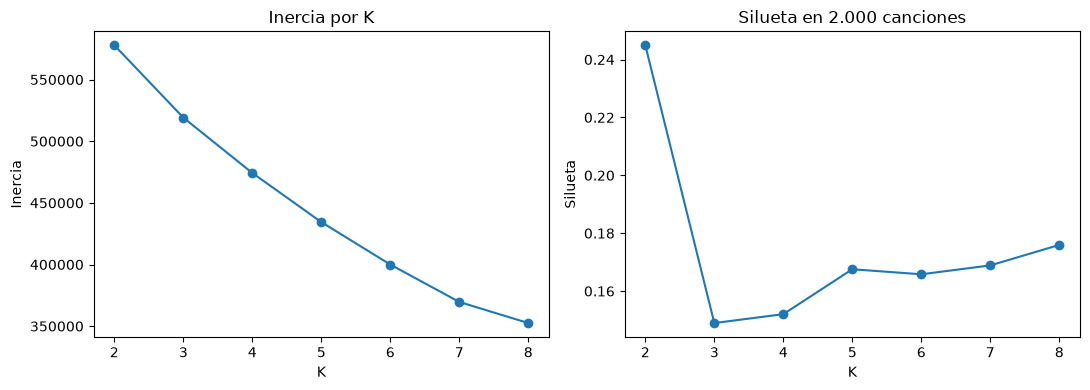

In [11]:
cluster_scaler = StandardScaler().fit(train_data[list(NUMERIC_FEATURES)])
cluster_features = cluster_scaler.transform(train_data[list(NUMERIC_FEATURES)])
sample_indices = np.random.default_rng(SEED).choice(
    len(train_data), size=min(2_000, len(train_data)), replace=False
)
cluster_rows = []
cluster_fits = {}
for k in range(2, 9):
    clustering = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_features)
    sample_labels = clustering.labels_[sample_indices]
    cluster_rows.append(
        {
            "K": k,
            "inercia": clustering.inertia_,
            "silueta_muestra": silhouette_score(cluster_features[sample_indices], sample_labels),
            "grupo_mínimo_pct": 100 * np.bincount(clustering.labels_).min() / len(train_data),
        }
    )
    cluster_fits[k] = clustering
cluster_evidence = pd.DataFrame(cluster_rows)
display(cluster_evidence.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_evidence["K"], cluster_evidence["inercia"], marker="o")
axes[0].set(title="Inercia por K", xlabel="K", ylabel="Inercia")
axes[1].plot(cluster_evidence["K"], cluster_evidence["silueta_muestra"], marker="o")
axes[1].set(title="Silueta en 2.000 canciones", xlabel="K", ylabel="Silueta")
plt.tight_layout()
plt.show()

La selección de K considera silueta, curva de inercia, tamaño mínimo e interpretabilidad del
perfil. La regla inicial toma el mayor valor de silueta entre soluciones con todos los grupos de al
menos 1% del entrenamiento; tras observar los perfiles se documenta si esa elección produce una
segmentación útil o solo separa extremos. No se usa `popularity` para cambiar K.

K elegido sin consultar popularity: 2


,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularidad_mediana,popularidad_media
cluster,,,,,,,,,,,,,
0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000,34.0,33.919
1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736,29.0,30.794


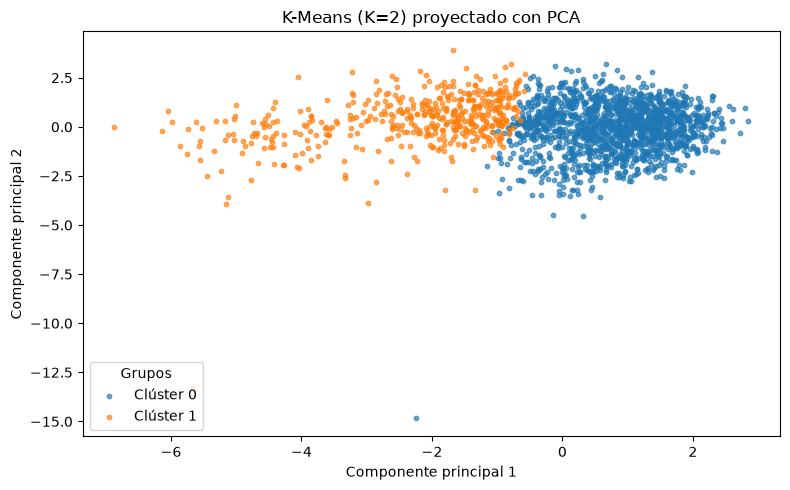

Varianza explicada por PCA: [0.289 0.152] ; suma: 0.441
Figura guardada en: reports\figures\ea2\04a_lucas_clusters_pca.png


In [12]:
eligible = cluster_evidence.loc[cluster_evidence["grupo_mínimo_pct"].ge(1)]
if eligible.empty:
    eligible = cluster_evidence
chosen_k = int(eligible.sort_values(["silueta_muestra", "K"], ascending=[False, True]).iloc[0]["K"])
chosen_clustering = cluster_fits[chosen_k]
cluster_profile = train_data[list(NUMERIC_FEATURES) + ["popularity"]].copy()
cluster_profile["cluster"] = chosen_clustering.labels_
sizes = cluster_profile.groupby("cluster").size().rename("canciones")
medians = cluster_profile.groupby("cluster")[list(NUMERIC_FEATURES)].median()
posthoc = cluster_profile.groupby("cluster")["popularity"].agg(
    popularidad_mediana="median", popularidad_media="mean"
)
profile = pd.concat([sizes, medians, posthoc], axis=1)
print(f"K elegido sin consultar popularity: {chosen_k}")
display(profile.round(3))

pca = PCA(n_components=2, random_state=SEED).fit(cluster_features)
sample_projection = pca.transform(cluster_features[sample_indices])
fig, ax = plt.subplots(figsize=(8, 5))
for cluster_id in range(chosen_k):
    mask = chosen_clustering.labels_[sample_indices] == cluster_id
    ax.scatter(
        sample_projection[mask, 0],
        sample_projection[mask, 1],
        color=plt.get_cmap("tab10")(cluster_id),
        s=10,
        alpha=0.65,
        label=f"Clúster {cluster_id}",
    )
ax.set(
    xlabel="Componente principal 1",
    ylabel="Componente principal 2",
    title=f"K-Means (K={chosen_k}) proyectado con PCA",
)
ax.legend(title="Grupos", loc="lower left")
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04a_lucas_clusters_pca.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(
    "Varianza explicada por PCA:",
    np.round(pca.explained_variance_ratio_, 3),
    "; suma:",
    round(pca.explained_variance_ratio_.sum(), 3),
)
print("Figura guardada en:", figure_path.relative_to(PROJECT_PATHS.root))

### Sensibilidad de K=2 a duración y `loudness`

Se conserva K=2, la semilla y el conjunto de entrenamiento. Primero se aplica `log1p` únicamente
a `duration_ms` antes de escalar; en un experimento separado se excluye `loudness`, manteniendo
las otras nueve variables. Cada escala y K-Means se reajusta desde cero. Se comparan silueta en
los mismos 2.000 IDs, tamaños y perfiles con medianas en unidades originales. La concordancia se
resume con ARI, que no depende del número arbitrario asignado a cada clúster. Para leer los
perfiles se alinean los nombres de los dos grupos buscando la mayor coincidencia de canciones;
este alineamiento no cambia las asignaciones ni el ARI. No se usa `popularity` para elegir o
ajustar grupos.

In [13]:
baseline_labels = chosen_clustering.labels_
numeric_original = train_data[list(NUMERIC_FEATURES)]
duration_log = numeric_original.copy()
duration_log["duration_ms"] = np.log1p(duration_log["duration_ms"])
without_loudness = numeric_original.drop(columns="loudness")

stability_rows = []
profile_rows = []
for variant, values in (
    ("original", numeric_original),
    ("duración_log1p", duration_log),
    ("sin_loudness", without_loudness),
):
    if variant == "original":
        labels = baseline_labels.copy()
        scaled_values = cluster_features
    else:
        scaled_values = StandardScaler().fit_transform(values)
        labels = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10).fit_predict(
            scaled_values
        )
        if np.mean(labels == baseline_labels) < 0.5:
            labels = 1 - labels
    sizes = np.bincount(labels, minlength=chosen_k)
    stability_rows.append(
        {
            "variante": variant,
            "variables": values.shape[1],
            "silueta_muestra": silhouette_score(
                scaled_values[sample_indices], labels[sample_indices]
            ),
            "ARI_vs_original": adjusted_rand_score(baseline_labels, labels),
            "coincidencia_pct": 100 * np.mean(baseline_labels == labels),
            "grupo_0": int(sizes[0]),
            "grupo_1": int(sizes[1]),
        }
    )
    original_with_group = numeric_original.copy()
    original_with_group["grupo"] = labels
    for group_id, group in original_with_group.groupby("grupo"):
        medians = group[list(NUMERIC_FEATURES)].median()
        profile_rows.append(
            {
                "variante": variant,
                "grupo": int(group_id),
                "canciones": len(group),
                **medians.to_dict(),
            }
        )

stability = pd.DataFrame(stability_rows)
stability_profiles = pd.DataFrame(profile_rows)
display(stability.round(3))
display(stability_profiles.round(3))

,variante,variables,silueta_muestra,ARI_vs_original,coincidencia_pct,grupo_0,grupo_1
0,original,10,0.245,1.000,100.000,54011,17781
1,duración_log1p,10,0.241,0.968,99.258,53954,17838
2,sin_loudness,9,0.209,0.807,95.194,51769,20023


,variante,grupo,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,original,0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000
1,original,1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736
2,duración_log1p,0,53954,217846.5,0.606,0.763,-6.137,0.054,0.077,0.000,0.144,0.525,125.000
3,duración_log1p,1,17838,196084.5,0.469,0.295,-13.014,0.040,0.829,0.004,0.116,0.268,107.598
4,sin_loudness,0,51769,217200.0,0.609,0.775,-6.089,0.056,0.067,0.000,0.147,0.532,125.024
5,sin_loudness,1,20023,200973.0,0.482,0.322,-11.858,0.039,0.804,0.001,0.116,0.287,108.184


### Hipótesis de uso para revisar el catálogo

Los dos perfiles pueden servir como **estratos de auditoría** del ranking retrospectivo. En una
revisión manual se tomaría una muestra del perfil energético/sonoro y otra del perfil
acústico/tranquilo, y se contaría en cada una cuántas canciones con popularidad ≥ 70 quedaron
fuera del 10% mejor puntuado. Si un perfil concentra omisiones, el equipo podría investigar
variables ausentes —por ejemplo, fecha y exposición— y comprobar la misma pregunta con datos más
representativos antes de cambiar una regla de selección. Esta es una **hipótesis por evaluar**:
el notebook no ha medido aún la cobertura del ranking por clúster. La silueta modesta y los cambios
al quitar `loudness` impiden tratar los grupos como categorías fijas para asignar promoción.

## 9. Interpretación, límites y entrega

**Comparación supervisada.** Ridge con géneros fue el candidato fijado en validación y obtuvo en
prueba MAE **11,915**, RMSE **16,643** y R² **0,348**. La referencia mediana tuvo MAE **17,250**:
la diferencia es **5,335 puntos** (30,9%) en esta partición. El árbol completo alcanzó MAE
**14,508**; por tanto, su capacidad para captar interacciones no compensó su mayor error aquí.
Esto no implica que Ridge funcione igual para artistas nuevos o canciones futuras.

**Aporte de géneros.** Al retirar solo `track_genres`, el MAE de Ridge subió de **11,915** a
**16,671** (4,756 puntos) y el del árbol de **14,508** a **15,693** (1,186 puntos). Los géneros
aportan mucha señal en esta muestra, especialmente al modelo lineal. Como la fuente contiene
exactamente 1.000 filas originales por género, la magnitud de esa ventaja puede reflejar el diseño
de muestreo. No es una estimación causal del efecto del género ni una ganancia garantizada fuera de
este dataset.

**Tres conjuntos en validación.** Con Ridge, `solo_audio` obtuvo MAE **16,630**,
`solo_géneros` **11,849** y `audio_y_géneros` **11,800**. El árbol obtuvo **15,686**, **14,472**
y **14,391**, respectivamente. Las etiquetas de género sostienen casi todo el rendimiento de
la combinación en esta validación; el aporte incremental de audio al MAE de Ridge es solo
**0,049 puntos**. El conjunto completo del protocolo, que añade variables categóricas, tuvo
MAE **11,786**. Estas comparaciones son descriptivas y no cuantifican cuánto cambiaría el error
con una distribución natural de géneros, desconocida en la fuente.

**Artistas principales nuevos.** La partición agrupada reservó **18.193 canciones** de **3.528**
artistas principales; otros **14.111** artistas principales quedaron en entrenamiento, sin
superposición entre ambos. Ajuste y validación agrupados contienen **57.176** y **14.371**
canciones, y la prueba queda identificada por SHA-256 en la salida. Ridge completo se seleccionó
de nuevo con `alpha=0,1` dentro de esa partición y obtuvo MAE **12,102**, RMSE **16,740** y
R² **0,302**, frente a MAE **16,707** de su referencia mediana. En la partición aleatoria,
Ridge completo obtuvo MAE **11,915** y R² **0,348**, con una referencia MAE **17,250**.
La mejora sobre la referencia fue **4,605** puntos (27,6%) por artista y **5,335** (30,9%)
aleatoriamente. Son conjuntos de prueba diferentes, por lo que esa diferencia no mide por sí
sola el efecto causal de excluir artistas conocidos. Además, **2.633 canciones** de la prueba
agrupada tienen un artista secundario presente en entrenamiento (en cualquier rol), aunque no
comparten artista principal. La prueba indica transferencia dentro de esta muestra a principales
no vistos bajo esa condición; no certifica transferencia a artistas totalmente nuevos ni corrige
el muestreo artificial por género.

**Errores y KPI.** Ridge completo tiene MAE **36,759** en las **653** canciones con popularidad
≥ 70, y **24,448** en las **1.863** de popularidad cero: el MAE global oculta extremos difíciles.
Todas las canciones ≥ 70 recibieron una predicción inferior a 70 (mediana **40,035**), con sesgo
medio de **−36,759** puntos. En cambio, las de popularidad cero recibieron mediana predicha
**23,369**. La concentración de predicciones alrededor de valores intermedios explica gran parte
de ambos errores: los atributos disponibles no distinguen bien un éxito excepcional o un cero
dentro de géneros y perfiles parecidos. Entre los **651** errores absolutos de al menos 40 puntos,
**236** corresponden a canciones ≥ 70 y **278** a canciones de popularidad cero. Ridge produce
**76 predicciones negativas** porque su salida lineal no está acotada al rango 0–100;
el diagnóstico no altera esas predicciones después de consultar la prueba.

En canciones explícitas el MAE es **14,198** frente a **11,704** en no explícitas; son grupos de
tamaños distintos y no se puede atribuir la diferencia a la explicitud. Entre las **1.795**
canciones mejor puntuadas, Ridge recuperó **159** de las **653** populares y dejó **494** fuera:
precisión **8,9%**, exhaustividad **24,3%** y *lift* **2,44** frente a la prevalencia de **3,64%**
en la prueba. Sin géneros recuperó **136** y logró *lift* **2,08**; el árbol recuperó **119** con
géneros y **82** sin ellos. La ordenación aporta señal relativa aunque los valores predichos estén
comprimidos. Supera una selección aleatoria de igual tamaño en esta muestra, pero no demuestra
utilidad comercial ni capacidad para pronosticar lanzamientos futuros.

**Clústeres.** K=2 tuvo la mayor silueta elegible (**0,245**), con **54.011** y **17.781**
canciones. El primer perfil es más energético y sonoro, con menor acousticness; el segundo es más
acústico y tranquilo. Sus medianas de popularidad, consultadas solo después de formar grupos, son
**34** y **29**. Al transformar duración con `log1p`, la silueta fue **0,241**, el ARI frente al
original **0,968** y coincidió el **99,258%** de las asignaciones tras alinear nombres. Al quitar
`loudness`, la silueta bajó a **0,209**, ARI **0,807** y coincidió el **95,194%**. En ambas
variantes se reconocen los perfiles energético y acústico, pero `loudness` afecta una fracción
apreciable de las asignaciones. La silueta original es modesta y la proyección PCA conserva solo
**44,1%** de la varianza. Son segmentos exploratorios dependientes de variables y escala, no
categorías musicales objetivas ni una explicación causal de la popularidad.

**Aplicación exploratoria.** Usar los perfiles energético/sonoro y acústico/tranquilo para auditar
si el 10% mejor puntuado deja fuera canciones populares de alguno de los dos grupos. Es una
pregunta concreta para una revisión humana; este notebook aún no calcula cobertura por clúster.
Antes de cambiar decisiones se requieren fechas, exposición y datos más representativos.

**Recomendación.** Usar estos resultados para formular preguntas y revisar el catálogo con criterio
humano, nunca para asignar automáticamente promoción. El notebook 05 deberá reproducir el
contraste por artista principal, el diagnóstico de errores y la sensibilidad de K-Means antes de
cerrar una conclusión del equipo. Los tres integrantes deben poder reproducir e interpretar estas
métricas y sus límites.